# Taak 4: GCMC van CH4 in IRMOF-1 met het baseline-krachtveld (DREIDING/UFF)

Alle functies staan in `src/gcmc.py`; dit notebook test ze en maakt de isotherm bij 298 K.

**Ontwerp**

- Toestand: array `ch4_positions` van N bij 3. Verplaatsing wijzigt een rij, insertie voegt een rij toe (N → N+1), deletie haalt er een weg (N → N−1).
- mu, V en T liggen vast, N fluctueert. De belading is ⟨N⟩ over de productiefase.
- Energie van een molecuul i = roosterterm (`energy_fast`, taak 2) + LJ met de *andere* CH4's (eps 158,5 K, sigma 3,72 A, zelfde cutoff en shift). Bij verplaatsing en deletie laat je molecuul i zelf weg uit die som (anders tel je zijn afstand 0 tot zichzelf); bij insertie bestaat het nieuwe molecuul nog niet, dus `others` is gewoon het hele huidige array.
- ΔU is lokaal: alleen de termen van het bewogen/ingevoegde/verwijderde molecuul veranderen. Bij deletie is ΔU = −U_i.
- Deletie bij N = 0: poging telt, wordt verworpen.
- Verplaatsing: uniform in [−d, d]³, d zo gekozen dat 30 à 50% wordt geaccepteerd; posities worden met modulo L in de cel teruggelegd.
- Acceptatie (Frenkel & Smit §6.5): insertie min(1, fV/((N+1)kT)·e^{−ΔU/T}), deletie min(1, NkT/(fV)·e^{−ΔU/T}), verplaatsing min(1, e^{−ΔU/T}); accepteren als een tweede random getal kleiner is. f in Pa, V in m³.
- Druk → fugaciteit met Peng-Robinson (`fugacity`), nodig boven ~5 bar.
- Eén `numpy.random.default_rng(seed)` voor alles, zodat een run reproduceerbaar is.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, "../src")
import numpy as np
import matplotlib.pyplot as plt
from energy import load_framework, load_force_field, pairwise_lj_params, energy_fast
from widom import widom, rho_framework, henry_coefficient, R
from gcmc import (energy_of_molecule, run_gcmc, block_average, total_energy, fugacity,
                  fugacity_coefficient, molecules_per_cell_to_mol_per_kg, CH4_EPS, CH4_SIGMA, K_B)

In [2]:
positions, symbols, L, masses = load_framework("../data/IRMOF-1.cif")
lj_params = load_force_field("../data/force_field/generic_dreiding_uff_mixing_rules.def")
eps_pair, sigma_pair = pairwise_lj_params(symbols, lj_params, guest=(CH4_EPS, CH4_SIGMA))
rho_fw = rho_framework(masses, L)
T = 298.0
V = (L * 1e-10) ** 3
print(f"L = {L:.3f} A, rho_fw = {rho_fw:.1f} kg/m3, 1 molecuul/cel = {molecules_per_cell_to_mol_per_kg(1, masses):.4f} mol/kg")

L = 25.832 A, rho_fw = 593.3 kg/m3, 1 molecuul/cel = 0.1624 mol/kg


/Users/kasperhuysentruyt/Documents/leven /Cusp/cusp-mlff-gcmc/.venv/lib/python3.14/site-packages/ase/io/cif.py:411: UserWarning: crystal system 'cubic' is not interpreted for space group Spacegroup(225, setting=1). This may result in wrong setting!
  warnings.warn(


## Tests

1. `energy_of_molecule` zonder andere CH4's moet exact `energy_fast` geven.
2. Boekhouding: de som van alle geaccepteerde ΔU moet gelijk zijn aan `total_energy(eind) − total_energy(start)`, met `total_energy` een trage, onafhankelijke dubbele lus. Dit test dat de lokale ΔU's onderling consistent zijn.
3. Fugaciteit: bij 40 bar en 298 K hoort f/p ≈ 0,92.

In [3]:
p_test = np.array([3.0, 4.0, 5.0])
assert np.isclose(energy_of_molecule(p_test, np.empty((0, 3)), positions, eps_pair, sigma_pair, L),
                  energy_fast(p_test, positions, eps_pair, sigma_pair, L))

rng = np.random.default_rng(1)
res = run_gcmc(positions, eps_pair, sigma_pair, L, T, f=10e5, n_steps=2000, rng=rng)
U_end = total_energy(res["ch4_positions"], positions, eps_pair, sigma_pair, L)
print(f"N_eind = {len(res['ch4_positions'])}, som dU = {res['sum_dU']:.4f} K, total_energy = {U_end:.4f} K, verschil = {U_end - res['sum_dU']:.1e} K")
assert np.isclose(U_end, res["sum_dU"], atol=1e-6)

for p_bar in (1, 5, 10, 20, 40):
    print(f"f/p({p_bar:2d} bar) = {fugacity_coefficient(p_bar * 1e5, T):.4f}")
print("alle tests ok")

N_eind = 23, som dU = -22115.9127 K, total_energy = -22115.9127 K, verschil = 2.9e-11 K
f/p( 1 bar) = 0.9978
f/p( 5 bar) = 0.9890
f/p(10 bar) = 0.9782
f/p(20 bar) = 0.9572
f/p(40 bar) = 0.9176
alle tests ok


## Check 1: lage druk, GCMC tegenover Henry (taak 3)

In het Henry-regime is ⟨N⟩ = fV/(kT) · ⟨exp(−U/T)⟩ met ⟨exp(−U/T)⟩ uit Widom. Bij 1 bar moet GCMC daar dicht bij zitten (iets erboven, want de CH4–CH4-aantrekking telt nu mee).

In [4]:
rng = np.random.default_rng(100)
boltzmann_mean, boltzmann_sem = widom(50_000, T, positions, eps_pair, sigma_pair, L, rng)
K_H = henry_coefficient(boltzmann_mean, T, rho_fw)
p = 1e5
n_henry = fugacity(p, T) * V / (K_B * T) * boltzmann_mean
print(f"Widom: <exp(-U/T)> = {boltzmann_mean:.3f} +- {boltzmann_sem:.3f}, K_H = {K_H:.3e} mol/kg/Pa")
print(f"Henry-voorspelling bij 1 bar: {n_henry:.3f} CH4/cel")

n_eq, n_steps, d = 20_000, 120_000, 1.5
rng = np.random.default_rng(42)
res = run_gcmc(positions, eps_pair, sigma_pair, L, T, f=fugacity(p, T), n_steps=n_steps, rng=rng,
               max_displacement=d, n_equilibration=n_eq)
n_mean, n_sem = block_average(res["n_history"])
print(f"GCMC bij 1 bar: <N> = {n_mean:.3f} +- {n_sem:.3f} CH4/cel, verhouding GCMC/Henry = {n_mean / n_henry:.3f}")
print("acceptatie:", {k: round(v, 3) for k, v in res["acceptance"].items()})

Widom: <exp(-U/T)> = 5.602 +- 0.064, K_H = 3.811e-06 mol/kg/Pa
Henry-voorspelling bij 1 bar: 2.342 CH4/cel


GCMC bij 1 bar: <N> = 2.383 +- 0.041 CH4/cel, verhouding GCMC/Henry = 1.018
acceptatie: {'translate': 0.476, 'insert': 0.338, 'delete': 0.341}


## Check 2: isotherm bij 298 K, 1 tot 40 bar

Per druk: fugaciteit via Peng-Robinson, 20.000 stappen equilibratie vanaf een lege cel, 100.000 stappen productie, foutbalk uit 10 blokgemiddelden. Belading absoluut, in moleculen per cel en in mol/kg.

In [5]:
pressures_bar = [1, 2, 5, 10, 20, 35, 40]
rows = []
traces = {}
for p_bar in pressures_bar:
    f = fugacity(p_bar * 1e5, T)
    rng = np.random.default_rng(42)
    res = run_gcmc(positions, eps_pair, sigma_pair, L, T, f=f, n_steps=n_steps, rng=rng,
                   max_displacement=d, n_equilibration=n_eq)
    n_mean, n_sem = block_average(res["n_history"])
    traces[p_bar] = res["n_history"]
    acc = res["acceptance"]
    rows.append((p_bar, f / 1e5, n_mean, n_sem, molecules_per_cell_to_mol_per_kg(n_mean, masses),
                 molecules_per_cell_to_mol_per_kg(n_sem, masses), acc["translate"], acc["insert"], acc["delete"]))
    print(f"{p_bar:3d} bar  f = {f/1e5:6.3f} bar  <N> = {n_mean:6.2f} +- {n_sem:4.2f}  "
          f"= {rows[-1][4]:5.2f} +- {rows[-1][5]:4.2f} mol/kg  acc T/I/D = {acc['translate']:.2f}/{acc['insert']:.2f}/{acc['delete']:.2f}")

isotherm = np.array(rows)
np.savetxt("../results/isotherm_uff_298K.csv", isotherm, delimiter=",",
           header="p_bar,f_bar,N_mean,N_sem,mol_per_kg,mol_per_kg_sem,acc_translate,acc_insert,acc_delete", comments="")

  1 bar  f =  0.998 bar  <N> =   2.38 +- 0.04  =  0.39 +- 0.01 mol/kg  acc T/I/D = 0.48/0.34/0.34


  2 bar  f =  1.991 bar  <N> =   4.85 +- 0.09  =  0.79 +- 0.01 mol/kg  acc T/I/D = 0.47/0.35/0.35


  5 bar  f =  4.945 bar  <N> =  12.07 +- 0.21  =  1.96 +- 0.03 mol/kg  acc T/I/D = 0.45/0.33/0.33


 10 bar  f =  9.782 bar  <N> =  23.68 +- 0.50  =  3.85 +- 0.08 mol/kg  acc T/I/D = 0.43/0.29/0.29


 20 bar  f = 19.143 bar  <N> =  43.93 +- 0.90  =  7.13 +- 0.15 mol/kg  acc T/I/D = 0.38/0.22/0.22


 35 bar  f = 32.452 bar  <N> =  67.43 +- 1.30  = 10.95 +- 0.21 mol/kg  acc T/I/D = 0.34/0.15/0.15


 40 bar  f = 36.705 bar  <N> =  75.80 +- 1.50  = 12.31 +- 0.24 mol/kg  acc T/I/D = 0.31/0.13/0.13


35 bar: GCMC hier 10.95 +- 0.21 mol/kg, Düren 2004 (DREIDING, eps_CH4 148 K) 9.70 mol/kg, verhouding 1.129; experiment (excess) 10.15 mol/kg


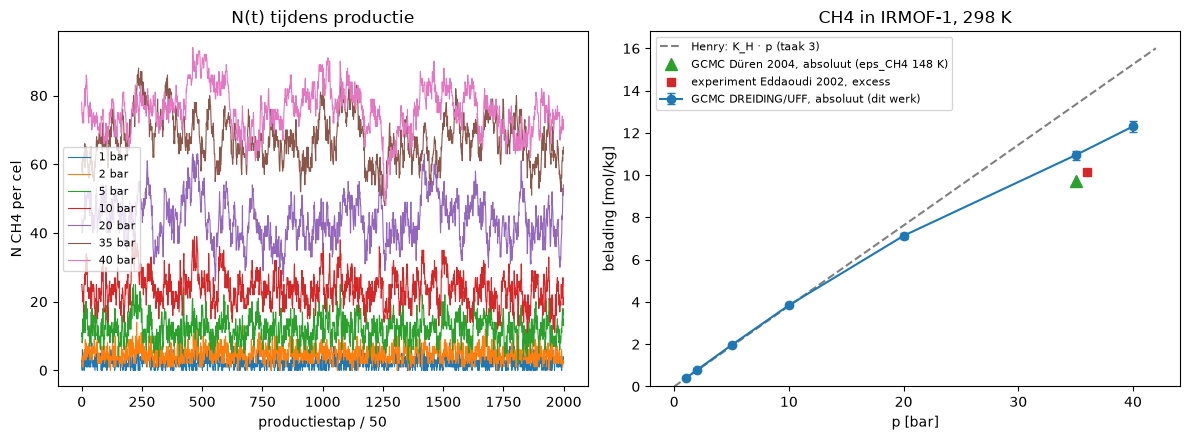

In [6]:
# Literatuur bij 35 bar (zie markdown hieronder)
duren_sim_mol_kg = 217.45 / 22414 * 1000          # Düren 2004, Tabel 1: 217,45 cm3(STP)/g, absoluut, GCMC DREIDING
eddaoudi_exp_mol_kg = 135 / 22414 / (rho_fw / 1000) * 1000   # Eddaoudi 2002: 135 cm3(STP)/cm3 bij 36 atm, excess
row35 = isotherm[isotherm[:, 0] == 35][0]
print(f"35 bar: GCMC hier {row35[4]:.2f} +- {row35[5]:.2f} mol/kg, Düren 2004 (DREIDING, eps_CH4 148 K) {duren_sim_mol_kg:.2f} mol/kg, "
      f"verhouding {row35[4] / duren_sim_mol_kg:.3f}; experiment (excess) {eddaoudi_exp_mol_kg:.2f} mol/kg")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for p_bar, trace in traces.items():
    ax1.plot(trace[::50], lw=0.8, label=f"{p_bar} bar")
ax1.set_xlabel("productiestap / 50")
ax1.set_ylabel("N CH4 per cel")
ax1.set_title("N(t) tijdens productie")
ax1.legend(fontsize=8)

p_grid = np.linspace(0, 42, 200)
ax2.errorbar(isotherm[:, 0], isotherm[:, 4], yerr=isotherm[:, 5], fmt="o-", capsize=3, label="GCMC DREIDING/UFF, absoluut (dit werk)")
ax2.plot(p_grid, K_H * p_grid * 1e5, "--", color="gray", label="Henry: K_H · p (taak 3)")
ax2.plot([35], [duren_sim_mol_kg], "^", color="C2", ms=8, label="GCMC Düren 2004, absoluut (eps_CH4 148 K)")
ax2.plot([36], [eddaoudi_exp_mol_kg], "s", color="C3", label="experiment Eddaoudi 2002, excess")
ax2.set_xlabel("p [bar]")
ax2.set_ylabel("belading [mol/kg]")
ax2.set_ylim(0, None)
ax2.set_title("CH4 in IRMOF-1, 298 K")
ax2.legend(fontsize=8)
fig.tight_layout()
fig.savefig("../results/isotherm_uff_298K.png", dpi=150)

## Vergelijking met literatuur

**Düren, Sarkisov, Yaghi, Snurr, *Langmuir* 2004, 20, 2683, Tabel 1** (GCMC, DREIDING all-atom voor het rooster, CH4 united atom met sigma 3,73 A en eps 148 K, cutoff 12,8 A, Lorentz-Berthelot, 298 K):

| grootheid IRMOF-1 | waarde |
|---|---|
| belading bij 35 bar, absoluut | 128,29 cm³(STP)/cm³ = 217,45 cm³(STP)/g = **9,70 mol/kg** |
| Q_st bij lage belading | 10,6 kJ/mol |
| V_free | 81% |
| rho_crys | 0,59 g/cm³ |

Experiment (Eddaoudi et al., *Science* 2002, 295, 469): ≈ 135 cm³(STP)/cm³ bij 36 atm, **excess**, ≈ 10,2 mol/kg. Düren rapporteert een gemiddelde afwijking simulatie/experiment van 5,7% (DREIDING) en 7,4% (UFF) over de hele isotherm.

**Hoe onze isotherm zich verhoudt** (getal hierboven geprint):

- Bij 1 bar valt GCMC binnen 2% samen met de Henry-lijn uit taak 3. Dat is de consistentiecheck tussen taak 3 en taak 4.
- Bij 35 bar zitten we ongeveer 13% boven Düren. De grootste oorzaak is het CH4-model: wij gebruiken eps = 158,5 K (Martin et al. 2001, via Dubbeldam 2007), Düren 148 K. Een 7% diepere put weegt exponentieel door in exp(−U/T) en dus in de belading. Daarnaast: Zn via UFF in plaats van DREIDING, cutoff 12 A met shift in plaats van 12,8 A zonder shift.
- Experiment meet excess, wij absoluut. Excess = absoluut − V_pore·rho_bulk. Met V_free 0,81 en bulk-CH4 bij 36 bar ≈ 1,5 mol/L is die correctie ≈ 2,1 mol/kg, dus ons absolute getal komt na correctie dicht bij het experiment uit.
- Een gepubliceerde K_H voor CH4 in IRMOF-1 met exact dit krachtveld is niet gevonden; Q_st 10,6 kJ/mol (Düren) is de dichtstbijzijnde lage-beladingsreferentie. De vergelijking loopt daarom via de isotherm.

**Beperkingen**: united-atom CH4, rigide rooster, geen elektrostatica, geen tail correction. Bij 40 bar daalt de insertie-acceptatie naar 13%, en 100.000 productiestappen geven daar een standaardfout van 2%; voor een publicatiekwaliteit-isotherm wil je 10× meer stappen (Düren: 500.000 + 500.000).